# 10 · Knowledge: RAG and agentic RAG, as graphs
Level L2 · Part 2 · core · ~40 min · builds on 09

## Goal
Answer from a real document instead of from memory. Build two graphs: an **ingest** graph that splits the FTC mail-order guide,
embeds each chunk and indexes it; and an **answer** graph that retrieves the best chunks, answers from them and cites the chunk.
Then let the agent decide when to search, which is agentic RAG.

## Why it matters
A model that answers from memory states rules as if it knows them. A rule about returns in your shop, or the FTC's rule for mail-order
goods, changes over time. A model answering from memory cannot tell you where a claim came from, and it can be wrong with confidence.

| Without retrieval | With retrieval |
|---|---|
| The answer comes from what the model remembers | The answer comes from chunks of the document you indexed |
| No source to check | Each claim carries the chunk it came from |
| A new edition means retraining, or a wrong answer | A new edition means re-indexing the changed chunks |

**What it makes easy:** answers you can check, and a document that changes without a new model. **When you don't need it:** a fact
the model is certain of and that never changes, or a short document you can paste into the prompt.

## The idea
An **embedding** is a list of numbers that a model computes from a text. Texts with similar meaning get similar lists, so the closest
chunks to a question are likely the ones that answer it. **Retrieval** picks the top chunks. **Agentic RAG** puts retrieval behind a
tool: the model searches when it needs to, and can search again with a different query.

## Picture
Two graphs. The ingest graph runs once per document; the answer graph runs per question. The drawing comes from `show_mermaid`, a
course helper in `graph_view.py` that turns a text diagram (Mermaid syntax) into a picture.

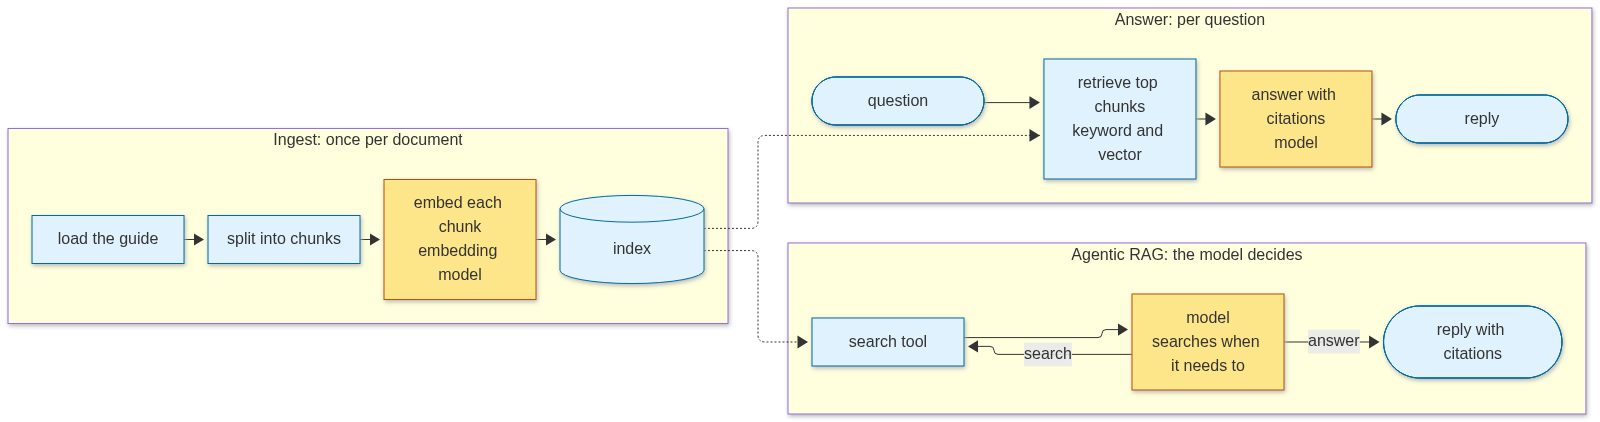

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  subgraph IN["Ingest: once per document"]
    L["load the guide"] --> S["split into chunks"] --> E["embed each chunk<br/>embedding model"] --> I[("index")]
  end
  subgraph AN["Answer: per question"]
    Q(["question"]) --> R["retrieve top chunks<br/>keyword and vector"] --> A["answer with citations<br/>model"] --> O(["reply"])
  end
  subgraph AG["Agentic RAG: the model decides"]
    M["model<br/>searches when it needs to"] -->|search| T["search tool"] --> M
    M -->|answer| F(["reply with citations"])
  end
  I -.-> R
  I -.-> T
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class E,A,M model
  class L,S,I,R,T,Q,O,F code
""")

## Step by step
Five steps, one cell each. The steps that call the model are tagged `needs-llm`. The course records each model answer the first time
it is made, so the notebook replays offline with no key. Three helpers appear below: `llm_replay` does that recording and replaying,
`get_llm` is the course's model setup, and `show_graph` draws a compiled LangGraph app, as `show_mermaid` drew the diagram above.

**Step 1 · the document and the splitter (no call).** The guide is the FTC's *Business Guide to the Mail, Internet or Telephone Order
Merchandise Rule*, about 5,000 words of US government text (public domain). It is saved in `data/`, and `data/SOURCES.md` gives its
source. The splitter cuts it into chunks of about 600 characters, overlapping by 80 so a sentence at a boundary is in two chunks.

In [2]:
from pathlib import Path
from langchain_text_splitters import RecursiveCharacterTextSplitter

TEXT = (Path("../../../data") / "ftc_30_day_rule.txt").read_text(encoding="utf-8")
splitter = RecursiveCharacterTextSplitter(chunk_size=600, chunk_overlap=80)
chunks = splitter.split_text(TEXT)
print(f"{len(TEXT)} characters → {len(chunks)} chunks · first chunk: {chunks[0][:90]}…")

30156 characters → 67 chunks · first chunk: How to Comply With the Rule

The following information will help you comply with the Rule.…


**Step 2 · the ingest graph (embedding requests, no answer call).** `split` makes one document per chunk, and `embed_and_index`
sends each chunk to the embedding model and stores it with its vector. The index is in memory here; a database would be the same
graph with a different last node. The cells below build it in four parts, starting with the imports.

In [3]:
import llm_replay  # course helper: records and replays the model calls of this notebook
llm_replay.start("10_rag-and-agentic-rag")

from typing_extensions import TypedDict
from langchain_core.documents import Document
from langchain_core.embeddings import Embeddings
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langgraph.graph import END, START, StateGraph
from llm_setup import get_llm
from graph_view import show_graph

LLM mode: replay (10_rag-and-agentic-rag.yaml)


The embedding model takes one text per request here, so a small wrapper sends the chunks one at a time. The model gives
768 numbers per vector.

In [4]:
EMBED_MODEL = "gemini-embedding-2"  # an embedding model, not the chat model: its name is not a secret


class OneAtATime(Embeddings):
    """This embedding model takes one text per request, so each chunk is sent on its own."""

    def __init__(self, base: GoogleGenerativeAIEmbeddings):
        self.base = base

    def embed_documents(self, texts: list[str]) -> list[list[float]]:
        return [self.base.embed_query(t) for t in texts]

    def embed_query(self, text: str) -> list[float]:
        return self.base.embed_query(text)


embedder = OneAtATime(GoogleGenerativeAIEmbeddings(model=EMBED_MODEL, vertexai=True, output_dimensionality=768))
index = InMemoryVectorStore(embedder)

The ingest graph has two nodes. The state holds the texts, then the documents.

In [5]:
class IngestState(TypedDict):
    texts: list
    docs: list


def split(state: IngestState) -> dict:
    return {"docs": [Document(page_content=t, metadata={"chunk": i}) for i, t in enumerate(state["texts"])]}


def embed_and_index(state: IngestState) -> dict:
    index.add_documents(state["docs"])  # embeds each chunk, then stores it with its vector
    return {}

Now wire the two nodes into a graph, run it on the chunks, and check the vectors.

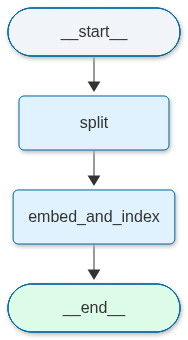

indexed 67 chunks · vectors of 768 numbers


In [6]:
ingest = StateGraph(IngestState)
ingest.add_node("split", split)
ingest.add_node("embed_and_index", embed_and_index)
ingest.add_edge(START, "split").add_edge("split", "embed_and_index").add_edge("embed_and_index", END)
ingest_app = ingest.compile()
show_graph(ingest_app)
ingest_app.invoke({"texts": chunks, "docs": []})
print(f"indexed {len(chunks)} chunks · vectors of {len(embedder.embed_query('check'))} numbers")

**Step 3 · retrieval: keyword and vector, fused.** Keyword search finds chunks that share the query's words. Vector search finds
chunks with similar meaning, and it needs the embedding model for the question. Each list is ranked, and the two ranks are fused: a
chunk high in either list rises. The keyword half and the fusion need no model, so check them by hand first.

In [7]:
import re


def keyword_rank(query: str, k: int) -> list[int]:
    words = set(re.findall(r"[a-z]{4,}", query.lower()))
    scored = [(len(words & set(re.findall(r"[a-z]{4,}", c.lower()))), i) for i, c in enumerate(chunks)]
    return [i for score, i in sorted(scored, key=lambda x: -x[0]) if score > 0][:k]


def fuse(*rankings: list[int], k: int = 3) -> list[int]:
    """Reciprocal rank fusion: each list adds 1 / (60 + rank) to a chunk's score."""
    score: dict[int, float] = {}
    for ranking in rankings:
        for rank, i in enumerate(ranking):
            score[i] = score.get(i, 0.0) + 1 / (60 + rank)
    return sorted(score, key=lambda i: -score[i])[:k]


QUESTION = "A customer ordered by phone and the item arrived late. Must the seller give a refund, and how fast?"
print("keyword top 3:", keyword_rank(QUESTION, 3))

keyword top 3: [58, 11, 31]


The vector half asks the embedding model for the question's vector and searches the index. That is one embedding request, not an
answer.

In [8]:
def hybrid(query: str, k: int = 3) -> list[int]:
    vector = [doc.metadata["chunk"] for doc in index.similarity_search(query, k=8)]
    return fuse(vector, keyword_rank(query, 8), k=k)


print("hybrid top 3:", hybrid(QUESTION))

hybrid top 3: [11, 24, 63]


**Step 4 · the answer graph: retrieve, then answer with citations (1 model call).** `retrieve` runs the hybrid search from Step 3.
`answer` gets only the retrieved chunks, and the prompt asks for the chunk number after each claim. A claim without a chunk number is
a claim to check.

In [9]:
from langchain_core.messages import HumanMessage

llm = get_llm()  # the course model, from llm_setup


class AnswerState(TypedDict):
    question: str
    chunk_ids: list
    answer: str


def retrieve(state: AnswerState) -> dict:
    return {"chunk_ids": hybrid(state["question"])}


def answer(state: AnswerState) -> dict:
    context = "\n".join(f"[chunk {i}] {chunks[i]}" for i in state["chunk_ids"])
    prompt = ("Answer the question using only the chunks. After each claim, give the chunk number in brackets, "
              "like [chunk 4]. If the chunks do not answer it, say so.\n\n"
              f"{context}\n\nQuestion: {state['question']}")
    return {"answer": llm.invoke([HumanMessage(content=prompt)]).text}

Gemini on Vertex AI · API key loaded: True


Wire the two nodes into a graph and run it on the question.

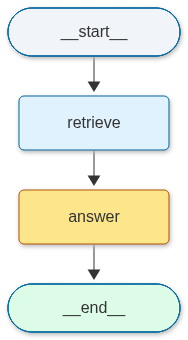

retrieved chunks: [11, 24, 63]
answer: If you cannot ship the order or provide a delay notice within the time originally promised (or within 30 days if no time was promised), you must cancel the order and make a prompt refund [chunk 11]. 

Additionally, you must cancel an order and provide a prompt refund if the customer exercises an option to cancel before you ship the merchandise, or if the customer does not respond to a first notice of a definite revised shipment date of 30 days or less and you have not shipped the merchandise or received consent for a further delay by that date [chunk 24].


In [10]:
rag = StateGraph(AnswerState)
rag.add_node("retrieve", retrieve)
rag.add_node("answer", answer)
rag.add_edge(START, "retrieve").add_edge("retrieve", "answer").add_edge("answer", END)
rag_app = rag.compile()
show_graph(rag_app, model_nodes=("answer",))
out = rag_app.invoke({"question": QUESTION, "chunk_ids": [], "answer": ""})
print("retrieved chunks:", out["chunk_ids"])
print("answer:", out["answer"])

**Step 5 · agentic RAG: the model decides when to search (2 model calls).** The search is a tool. The model may search, read the chunks,
and search again with different words if the first results do not answer. The loop is the one from lesson 05, with a search tool.

In [11]:
from langchain_core.tools import tool
from langgraph.prebuilt import ToolNode, tools_condition


@tool
def search_guide(query: str) -> str:
    """Search the FTC mail-order guide. Use it for any rule about delivery, refunds or returns. Returns numbered chunks."""
    return "\n".join(f"[chunk {i}] {chunks[i]}" for i in hybrid(query))


model = llm.bind_tools([search_guide])  # the model may ask for a search; the docstring above tells it when


def call_model(state: dict) -> dict:
    return {"messages": [model.invoke(state["messages"])]}

Wire the model and the search tool into a loop. The model either asks for a search (the `tools` node runs it) or answers (the run
stops).

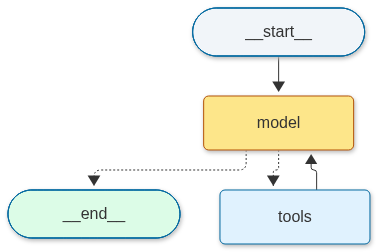

In [12]:
from langgraph.graph import MessagesState

agentic = StateGraph(MessagesState)
agentic.add_node("model", call_model)
agentic.add_node("tools", ToolNode([search_guide]))  # runs the search the model asked for
agentic.add_edge(START, "model")
agentic.add_conditional_edges("model", tools_condition, {"tools": "tools", END: END})
agentic.add_edge("tools", "model")
agentic_app = agentic.compile()
show_graph(agentic_app, model_nodes=("model",))

Run the loop on the question. The `recursion_limit` caps the number of steps, so a loop that never answers stops with an error.

In [13]:
final = agentic_app.invoke({"messages": [HumanMessage(content=QUESTION + " Cite the chunk numbers.")]},
                           config={"recursion_limit": 8})  # a hard stop on the number of steps
for m in final["messages"][1:]:
    for call in getattr(m, "tool_calls", []) or []:
        print("the model searches for:", call["args"])
print("answer:", final["messages"][-1].text)
llm_replay.stop()  # saves the recording; the last model call of this lesson

the model searches for: {'query': 'phone order late delivery refund requirements'}
answer: According to the FTC’s Mail, Internet, or Telephone Order Merchandise Rule, the seller's obligations regarding refunds for late shipments are as follows:

*   **When a refund is required:** If a seller cannot ship an order by the time they originally promised (or within 30 days if no time was promised), and they cannot provide a valid delay notification within that timeframe, they must cancel the order and provide a refund. Additionally, if a seller determines they will never be able to ship the order, they must cancel it and provide a full refund **[chunk 9, chunk 11]**.
*   **How fast:** The rule requires that refunds be made "promptly" **[chunk 9, chunk 11, chunk 17]**.

In summary, if the seller fails to meet the shipping deadline or the required notification timeline, they are obligated to cancel the order and issue a prompt refund **[chunk 11]**.


## At work
- Teams keep the source of every chunk and show it to the reviewer. A claim without a source is treated as unverified → lesson 32
  (evals: groundedness).
- Embeddings are cheap per document, so the ingest runs once and the answers reuse it. A changed document re-embeds only the changed chunks.
- A search that returns nothing relevant must say so. The prompt in Step 4 allows that answer; an eval checks that the agent uses it.

## What just happened
- The splitter cut 30,156 characters into 67 chunks, and the index holds 67 vectors of 768 numbers each.
- Keyword search ranked chunks 58, 11 and 31 first. The fused hybrid search ranked 11, 24 and 63, so chunk 11 moved to the top.
- The answer graph retrieved chunks 11, 24 and 63, and its answer cites chunk 11 and chunk 24.
- The agentic run made one search, for "phone order late delivery refund requirements", and its answer cites chunks 9, 11 and 17.
  The model searched once; it would search again only if the first results did not answer.

## Common mistakes
1. **Chunks cut in the middle of a rule.** Overlap helps, but a chunk size that is too small splits a sentence from its exception.
2. **Trusting one search.** A first query can miss the words the document uses. Agentic RAG lets the model search again.
3. **Mixing the embedding model with the answer model.** Vectors from different embedding models cannot be compared, and the code
   below shows the error you get when the sizes differ. Keep one embedding model for the index, and re-embed the whole index when
   you change it.

In [14]:
import numpy as np

index_vector = np.zeros(768)   # a vector from the index: 768 numbers
question_vector = np.zeros(3)  # a vector from a model with 3 numbers
try:
    np.dot(index_vector, question_vector)  # the score that compares the two
except ValueError as err:
    print(type(err).__name__, "-", str(err).splitlines()[0])

ValueError - shapes (768,) and (3,) not aligned: 768 (dim 0) != 3 (dim 0)


## Try it
Write `fuse_two(a, b)` that calls `fuse` with two rankings and returns the top 2. Test it on `[1, 2, 3]` and `[3, 1, 4]`. Which chunk
comes first, and why? No model call is needed.

In [15]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [16]:
def fuse_two(a: list[int], b: list[int]) -> list[int]:
    return fuse(a, b, k=2)


print(fuse_two([1, 2, 3], [3, 1, 4]))  # [1, 3]: chunk 1 is first in one list and second in the other; chunk 3 is third in one and first in the other, so 1 wins by a small margin

[1, 3]


## Key terms
- **Chunk** — a piece of the document, about 600 characters here, that is indexed and retrieved as one unit.
- **Embedding** — a list of numbers a model computes from a text; similar meanings give similar lists.
- **Index** — the store of chunks and their vectors that the search runs against.
- **Vector search** — finding the chunks whose vectors are closest to the question's vector.
- **Keyword search** — finding the chunks that share words with the question.
- **Rank fusion** — combining several ranked lists into one; here each list adds 1 / (60 + rank) to a chunk's score.
- **RAG** — retrieval-augmented generation: retrieve chunks first, then answer from them.
- **Agentic RAG** — retrieval as a tool the model calls when it needs to, possibly more than once.
- **Citation** — the chunk number given after each claim, so a reviewer can check it.

## Recap
- An ingest graph splits, embeds and indexes a document once. An answer graph retrieves and answers with citations.
- Keyword and vector ranks are fused, so a chunk high in either list rises.
- Agentic RAG makes the search a tool, so the model can search again with other words.

**Interview:** "How do you make an agent answer from a policy document, and prove where each claim came from?" Strong answer: "I split and
embed the document once, retrieve with keyword and vector search fused, and answer with the chunk number after each claim. The agent
can search again when the first results miss."